# Εργασία 4 - Naive Bayes

Author: Evangelos Michelis Kotronidis
Date: 6-11-2026

## Εισαγωγή βιβλιοθηκών και εισαγωγή δεδομένων

In [46]:
import pandas as pd
import numpy as np
import os
import sys
import nltk
import string
import matplotlib.pyplot as plt
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.stem import PorterStemmer
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('averaged_perceptron_tagger_eng')


train = pd.read_csv("/content/train.csv")
test = pd.read_csv("/content/test.csv")

print(train.head())
print(test.head())
print("Train shape:", train.shape)
print("Test shape:", test.shape)


   id keyword location                                               text  \
0   1     NaN      NaN  Our Deeds are the Reason of this #earthquake M...   
1   4     NaN      NaN             Forest fire near La Ronge Sask. Canada   
2   5     NaN      NaN  All residents asked to 'shelter in place' are ...   
3   6     NaN      NaN  13,000 people receive #wildfires evacuation or...   
4   7     NaN      NaN  Just got sent this photo from Ruby #Alaska as ...   

   target  
0       1  
1       1  
2       1  
3       1  
4       1  
   id keyword location                                               text
0   0     NaN      NaN                 Just happened a terrible car crash
1   2     NaN      NaN  Heard about #earthquake is different cities, s...
2   3     NaN      NaN  there is a forest fire at spot pond, geese are...
3   9     NaN      NaN           Apocalypse lighting. #Spokane #wildfires
4  11     NaN      NaN      Typhoon Soudelor kills 28 in China and Taiwan
Train shape: (7613, 5

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!


## Ερώτημα 1 - Διαχώρισμος dataset 90%-10% και γραφήματα

In [47]:

X = train.drop("target", axis=1)
y = train["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.10,
    stratify=y,
    random_state=0
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

Training set: (6851, 4)
Testing set: (762, 4)


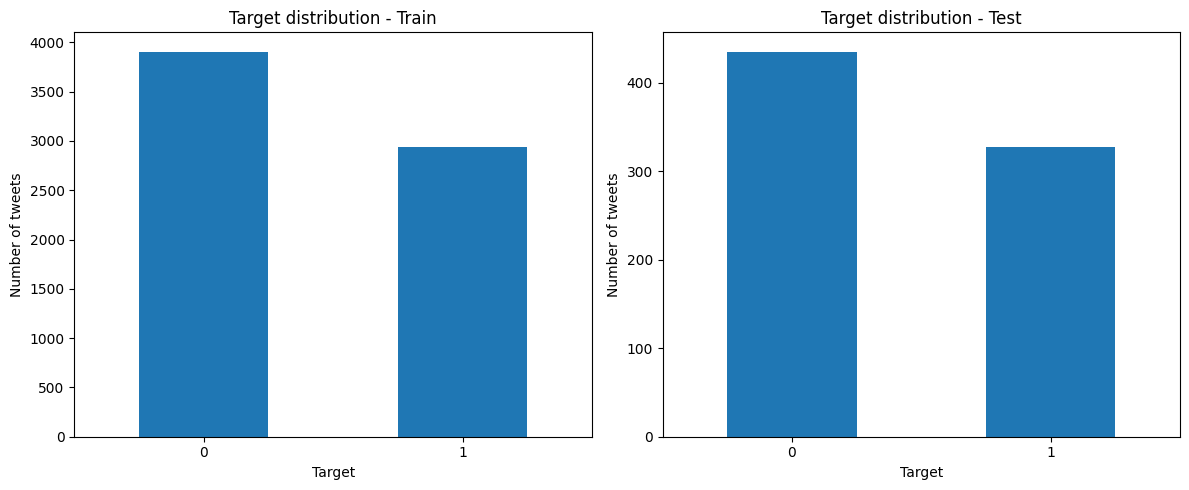

Train distribution:
target
0    3907
1    2944
Name: count, dtype: int64

Test distribution:
target
0    435
1    327
Name: count, dtype: int64


In [48]:
train_counts = y_train.value_counts().sort_index()
test_counts = y_test.value_counts().sort_index()
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

train_counts.plot(kind="bar", ax=axes[0])
axes[0].set_title("Target distribution - Train")
axes[0].set_xlabel("Target")
axes[0].set_ylabel("Number of tweets")
axes[0].set_xticklabels(["0", "1"], rotation=0)

test_counts.plot(kind="bar", ax=axes[1])
axes[1].set_title("Target distribution - Test")
axes[1].set_xlabel("Target")
axes[1].set_ylabel("Number of tweets")
axes[1].set_xticklabels(["0", "1"], rotation=0)

plt.tight_layout()
plt.show()

print("Train distribution:")
print(train_counts)

print("\nTest distribution:")
print(test_counts)


### Σχόλιο για ισορροπία σετ δεδομένων

Από τα γραφήματα για train και test set, φαίνεται ότι είναι ισορροπημένο το dataset, καθώς η αναλογία ανάμεσα στις δύο κλάσεις και στα δυο σετ είναι σχεδόν ίδια, χωρίς ωστόσο να είναι ίσο και το πλήθος των παρατηρήσεων.

## Ερώτημα 2 - Επεξεργασία δεδομένων

In [49]:
X_train = X_train.copy()
X_test = X_test.copy()

X_train = X_train.drop(columns=["id", "location"])
X_test = X_test.drop(columns=["id", "location"])

X_train = X_train.fillna("null")
X_test = X_test.fillna("null")

X_train["inputs"] = X_train["keyword"] + " " + X_train["text"]
X_test["inputs"] = X_test["keyword"] + " " + X_test["text"]

X_train = X_train[["inputs"]]
X_test = X_test[["inputs"]]

print(X_train.head())
print(X_test.head())


                                                 inputs
6669  threat Meek Mill responds to DrakeÛªs OVO Fes...
3940  flood survived the plague\nfloated the flood\n...
7217  weapons #Kick Hendrixonfire  @'=BLACKCATS= | B...
2234  deluge Vince McMahon once again a billionaire:...
4233  hazardous Is it possible to sneak into a hospi...
                                                 inputs
604   bioterror #FedEx no longer to transport bioter...
5374  panic Panic over: Patient in Alabama tests neg...
3022  dust%20storm New Mad Max Screenshots Show Off ...
3357  evacuated Rocky fire in Northern California sw...
4726  lava @YoungHeroesID Lava Blast &amp; Power Red...


## Ερώτημα 3 - Επεξεργασία κειμένων και αφαίρεση περιττών πληροφοριών

In [50]:

repo_path = "/content/text-preprocessing-techniques"
os.chdir(repo_path)

if repo_path not in sys.path:
    sys.path.insert(0, repo_path)

import techniques as tp

print("Repository imported successfully!")

Repository imported successfully!


In [51]:
stoplist = stopwords.words('english')
lemmatizer = WordNetLemmatizer()
stemmer = PorterStemmer()

allowedWordTypes = ["J", "R", "V", "N"]


def preprocess_text(text):
    text = tp.removeUnicode(text)
    text = tp.replaceURL(text)
    text = tp.replaceAtUser(text)
    text = tp.removeHashtagInFrontOfWord(text)
    text = tp.replaceSlang(text)
    text = tp.replaceContraction(text)
    text = tp.removeNumbers(text)
    text = tp.replaceMultiExclamationMark(text)
    text = tp.replaceMultiQuestionMark(text)
    text = tp.replaceMultiStopMark(text)
    text = tp.removeEmoticons(text)
    text = text.lower()
    tokens = nltk.word_tokenize(text)
    tokens = tp.replaceNegations(tokens)
    tokens = [
        word.translate(str.maketrans('', '', string.punctuation))
        for word in tokens
    ]

    tagged_words = nltk.pos_tag(tokens)

    final_words = []

    for word, tag in tagged_words:

        if tag[0] in allowedWordTypes and word not in stoplist:
            word = tp.replaceElongated(word)

            if len(word) > 1:
                word = lemmatizer.lemmatize(word)
                word = stemmer.stem(word)
                final_words.append(word)

    return " ".join(final_words)


In [52]:
X_train["inputs"] = X_train["inputs"].apply(preprocess_text)
X_test["inputs"] = X_test["inputs"].apply(preprocess_text)
print(X_train["inputs"].head(10))

6669    threat meek mill respond drake ovo fest set we...
3940    flood surviv plagu float flood peek head mud o...
7217    weapon kick hendrixonfir atus big nob conquest...
2234    delug vinc mcmahon billionair rememb read delu...
4233    hazard possibl sneak hospit stab hazard needl ...
6050    sinkhol larg sinkhol swallow entir pond lownd ...
6518    surviv go year separ sometim let man know leav...
1290    burn atus atus keithi getin burn block social ...
5967                    scream atus scream babi love much
2623                   destruct differ caus self destruct
Name: inputs, dtype: object


### Περιγραφή τεχνικών

Unicode normalization: Απομάκρυνση μη-απαραίτητων unicode χαρακτήρων

Lowercase: ενοποίηση κεφαλαίων και πεζών γραμματών

URL removal: αφαίρεση υπερσυνδέσμων

Mention removal: αφαίρεση ονομάτων χρηστών

Hashtag removal: αφαίρεση hashtag

Slang removal: Αντικατάσταση συντομευμένων εκφράσεων

Contraction replacement: Ανάπτυξη συντομευμένων εκφράσεων

Number removal: αφαίρεση αριθμών

Punctuation removal: αφαίρεση
σημείων στίξης

Emoticon removal: αφαίρεση emojis

Negation handling: επεξεργασία αρνητικών εκφράσεων

POS tagging: αναγνώριση της γραμματικής κατηγορίας των λέξεων

Stopword removal: αφαίρεση συχνών λέξεων που δεν προσφέρουν χρήσιμη πληροφορία

Lemmatization: μετατροπή των λέξεων στην αρχική τους μορφή

Stemming: μετατροπή των λέξεων στη ρίζα τους

Whitespace normalization: αφαίρεση περιττών κενών

## Ερώτημα 4 - Διαχωρισμός inputs, targets

In [53]:
inputs_train = X_train["inputs"].values
inputs_test = X_test["inputs"].values

targets_train = y_train.values
targets_test = y_test.values

print("Inputs train:", inputs_train.shape)
print("Inputs test:", inputs_test.shape)

print("Targets train:", targets_train.shape)
print("Targets test:", targets_test.shape)


Inputs train: (6851,)
Inputs test: (762,)
Targets train: (6851,)
Targets test: (762,)


## Ερώτημα 5 - TF-iDF

In [54]:
vectorizer = TfidfVectorizer(
    max_features=5000
)

X_train_tfidf = vectorizer.fit_transform(inputs_train)
X_test_tfidf = vectorizer.transform(inputs_test)

print("TF-IDF train shape:", X_train_tfidf.shape)
print("TF-IDF test shape:", X_test_tfidf.shape)

TF-IDF train shape: (6851, 5000)
TF-IDF test shape: (762, 5000)


## Ερώτημα 6 - Εκπαίδευση Gaussian Naive Bayes

In [55]:
X_train_dense = X_train_tfidf.toarray()
X_test_dense = X_test_tfidf.toarray()

model = GaussianNB()

model.fit(X_train_dense, targets_train)

predictions = model.predict(X_test_dense)

print("Predictions:")
print(predictions[:20])


Predictions:
[1 1 0 1 1 0 1 0 1 0 1 1 1 1 1 0 1 1 0 1]


### Αξιολόγηση αποτελεσμάτων

Accuracy: 0.5984251968503937

Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.40      0.53       435
           1       0.52      0.87      0.65       327

    accuracy                           0.60       762
   macro avg       0.66      0.63      0.59       762
weighted avg       0.68      0.60      0.58       762



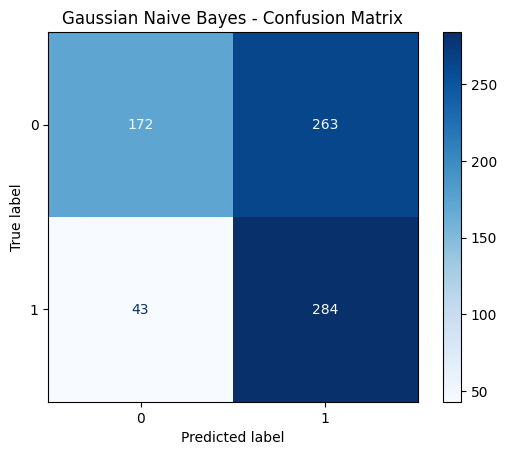

In [56]:
accuracy = accuracy_score(targets_test, predictions)

print("Accuracy:", accuracy)

print("\nClassification Report:")
print(classification_report(targets_test, predictions))

cm = confusion_matrix(targets_test, predictions)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[0, 1]
)

disp.plot(cmap="Blues")
plt.title("Gaussian Naive Bayes - Confusion Matrix")
plt.show()


### Σχολιασμός Classification Report

Η ακρίβεια (59,84%) είναι σχετικά χαμηλή, όπου το μοντέλο ταξινόμησε σωστά περίπου 60% των tweet του test set.

Στον δείκτη precision, τα tweet που χαρακτηρίστηκαν ως μη-σχετικά με τις φυσικές καταστροφές, το 80% ταξινομήθηκε σωστά. Από τα tweet που είχαν σχέση με τις φυσικές καταστροφές, μόνο το 52% ταξινομήθηκε σωστά.

Για τον δείκτη recall, το μοντέλο εντοπίζει μόνο το 40% των πραγματικών tweet που δεν αφορούν σε φυσικές καταστροφές και το 87% των tweet που αφορούν σε φυσικές καταστροφές.

Ο δείκτης F1-score είναι συνδυασμός των Precision και Recall και αποτελεί μέτρο συνολικής σύγκρισης για κάθε κατηγορία και φαίνεται να έχει καλύτερη απόδοση στη δεύτερη κατηγορία (0,65).

Εν ολίγοις, βάσει ακρίβειας είναι ένα μέτριο μοντέλο, αλλά λόγω του υψηλού Recall, μπορεί να εντοπίζει τα περισσότερα σχετικά tweet. Ωστόσο, μπορεί να παράγει και αρκετές ψευδώς θετικές προβλέψεις.